# 06 — Ajuste de Hiperparâmetros

No notebook 05, a validação cruzada confirmou o melhor modelo da trilha: a **random forest + atributos**, com **MAE de 0,315 ± 0,006**. Mas até agora usamos a floresta com as **configurações padrão** do scikit-learn. Também vimos um grande overfitting: erro de 0,12 no treino contra 0,32 na validação.

Será que outras configurações funcionam melhor? Neste notebook você vai aprender:

- Os principais **hiperparâmetros** da random forest e o que cada um controla
- Como acessar hiperparâmetros **dentro de um Pipeline** (a notação `modelo__nome`)
- **Busca em grade** (`GridSearchCV`): testar todas as combinações
- **Busca aleatória** (`RandomizedSearchCV`): testar combinações sorteadas
- Por que o melhor resultado de uma busca é **otimista**
- Quando vale (e quando **não** vale) a pena ajustar hiperparâmetros

> ⏱️ Este notebook treina **centenas** de florestas. Ele leva alguns minutos para rodar inteiro. Enquanto uma célula roda, aparece `[*]` à esquerda dela.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_validate, validation_curve
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

# Ferramentas novas deste notebook:
from sklearn.model_selection import GridSearchCV         # busca em grade
from sklearn.model_selection import RandomizedSearchCV   # busca aleatória
from scipy.stats import randint, uniform                 # "sorteadores" de números (distribuições)

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# O mesmo teste guardado de sempre. Ele não será usado neste notebook.
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# As mesmas 5 dobras do notebook 05, para os resultados serem comparáveis.
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

In [2]:
SAO_FRANCISCO = (37.77, -122.42)
LOS_ANGELES = (34.05, -118.24)


def criar_derivados(X):
    """Proporções: quartos por cômodo e cômodos por morador."""
    X = X.copy()
    X["BedrmsPerRoom"] = X["AveBedrms"] / X["AveRooms"]
    X["RoomsPerPerson"] = X["AveRooms"] / X["AveOccup"]
    return X


def criar_dist_cidade(X):
    """Distância aproximada (em graus) até a cidade grande mais próxima."""
    X = X.copy()
    dist_sf = np.sqrt((X["Latitude"] - SAO_FRANCISCO[0]) ** 2 + (X["Longitude"] - SAO_FRANCISCO[1]) ** 2)
    dist_la = np.sqrt((X["Latitude"] - LOS_ANGELES[0]) ** 2 + (X["Longitude"] - LOS_ANGELES[1]) ** 2)
    X["DistCidade"] = np.minimum(dist_sf, dist_la)
    return X


# O melhor modelo do notebook 04, com todos os hiperparâmetros no valor padrão.
pipeline = Pipeline([
    ("derivados", FunctionTransformer(criar_derivados)),
    ("dist_cidade", FunctionTransformer(criar_dist_cidade)),
    ("modelo", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
])

## 2. Ponto de partida: a floresta com configurações padrão

Vamos criar uma função para avaliar uma configuração com validação cruzada e guardar o resultado num placar.

In [3]:
placar = {}   # nome da configuração -> resultados


def avaliar_cv(nome, modelo):
    """Avalia um modelo com as 5 dobras, guarda no placar e mostra o resumo."""
    inicio = time.time()
    cv = cross_validate(modelo, X_train_full, y_train_full, cv=kfold,
                        scoring="neg_mean_absolute_error", return_train_score=True)
    placar[nome] = {
        "MAE validação": -cv["test_score"].mean(),
        "± desvio": cv["test_score"].std(),
        "MAE treino": -cv["train_score"].mean(),
        "tempo (s)": time.time() - inicio,
        "_por_dobra": -cv["test_score"],   # guardado para a comparação pareada no final
    }
    r = placar[nome]
    print(f"{nome}: MAE {r['MAE validação']:.4f} ± {r['± desvio']:.4f}  "
          f"(treino {r['MAE treino']:.3f}, {r['tempo (s)']:.1f} s)")


avaliar_cv("Padrão", pipeline)

Padrão: MAE 0.3152 ± 0.0058  (treino 0.117, 9.2 s)


**Conclusão:** o mesmo resultado do notebook 05: MAE de **0,3152 ± 0,0058** na validação e 0,117 no treino. Esse é o número a ser batido. (Neste notebook usamos 4 casas decimais, porque as diferenças vão ser pequenas.)

## 🎓 Conceito: os hiperparâmetros da random forest

Lembrando do notebook 04: **parâmetros** o modelo aprende sozinho (as perguntas de cada árvore); **hiperparâmetros** nós escolhemos antes de treinar. A random forest tem vários. Os mais importantes são:

| Hiperparâmetro | O que controla | Padrão | Efeito de aumentar |
|---|---|---|---|
| `n_estimators` | Número de árvores | 100 | Mais estável, mais lento. Não causa overfitting (notebook 04) |
| `max_features` | Fração das colunas que cada pergunta pode considerar | 1.0 (todas) | Árvores mais **parecidas** entre si |
| `min_samples_leaf` | Mínimo de casas em cada folha | 1 | Árvores mais **simples**, menos overfitting |
| `max_depth` | Profundidade máxima de cada árvore | None (sem limite) | Árvores mais **complexas** |

O `max_features` merece atenção. No notebook 04, vimos que a floresta funciona porque as árvores **erram de formas diferentes**. Com `max_features=1.0`, toda pergunta pode escolher entre todas as colunas, e todas as árvores tendem a começar perguntando sobre `MedInc`. Limitar as colunas **força a diversidade**: algumas árvores precisam encontrar outros caminhos.

O problema é que esses hiperparâmetros **interagem**: o melhor `min_samples_leaf` pode depender do `max_features`. Vamos primeiro entender cada um sozinho e depois buscar as combinações.

## 3. Hiperparâmetros dentro de um Pipeline

Nosso modelo está **dentro** de um pipeline, na etapa chamada `"modelo"`. Para acessar um hiperparâmetro dele, o scikit-learn usa a notação **`etapa__hiperparametro`**, com **dois** sublinhados:

```
modelo__max_features
└─┬──┘  └────┬─────┘
 nome da     nome do
 etapa       hiperparâmetro
```

In [4]:
# get_params() lista TODOS os hiperparâmetros do pipeline e de suas etapas.
# Filtramos só os da floresta que vamos ajustar.
todos = pipeline.get_params()
for nome in ["modelo__n_estimators", "modelo__max_features", "modelo__min_samples_leaf", "modelo__max_depth"]:
    print(f"{nome:<26} = {todos[nome]}")

modelo__n_estimators       = 100
modelo__max_features       = 1.0
modelo__min_samples_leaf   = 1
modelo__max_depth          = None


Para **mudar** um hiperparâmetro, usamos `set_params` com a mesma notação: `pipeline.set_params(modelo__max_features=0.5)`. Vamos usar isso a seguir.

## 4. Um hiperparâmetro de cada vez

In [5]:
from sklearn.base import clone


def curva(hiperparametro, valores):
    """Validação cruzada para cada valor de um hiperparâmetro (os outros ficam no padrão)."""
    # validation_curve (notebook 05) aceita a notação "etapa__hiperparametro".
    scores_treino, scores_val = validation_curve(
        clone(pipeline), X_train_full, y_train_full,
        param_name=hiperparametro, param_range=valores,
        cv=kfold, scoring="neg_mean_absolute_error",
    )
    return -scores_treino.mean(axis=1), -scores_val.mean(axis=1), scores_val.std(axis=1)


valores_features = [0.2, 0.33, 0.5, 0.75, 1.0]
valores_folha = [1, 2, 4, 8, 16]

inicio = time.time()
treino_f, val_f, desvio_f = curva("modelo__max_features", valores_features)
treino_l, val_l, desvio_l = curva("modelo__min_samples_leaf", valores_folha)
print(f"50 florestas treinadas em {time.time() - inicio:.0f} s")

50 florestas treinadas em 69 s


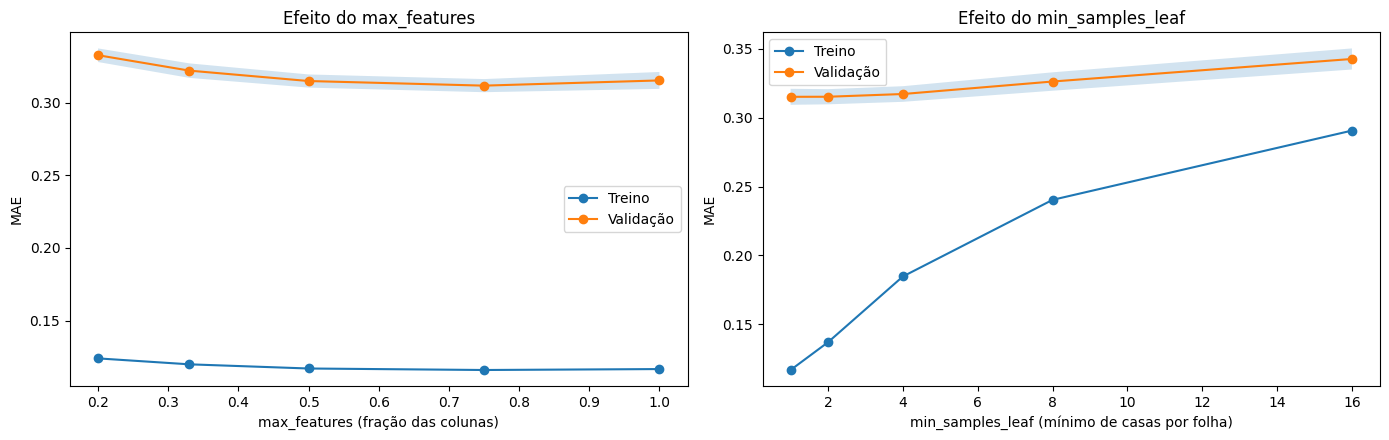

              MAE validação  ± desvio  MAE treino
max_features                                     
0.20                 0.3325    0.0047      0.1240
0.33                 0.3219    0.0050      0.1199
0.50                 0.3148    0.0045      0.1171
0.75                 0.3116    0.0045      0.1160
1.00                 0.3152    0.0058      0.1167

                  MAE validação  ± desvio  MAE treino
min_samples_leaf                                     
1                        0.3152    0.0058      0.1167
2                        0.3152    0.0055      0.1369
4                        0.3172    0.0057      0.1846
8                        0.3263    0.0067      0.2403
16                       0.3427    0.0077      0.2906


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

graficos = [
    (axes[0], valores_features, treino_f, val_f, desvio_f, "max_features (fração das colunas)"),
    (axes[1], valores_folha, treino_l, val_l, desvio_l, "min_samples_leaf (mínimo de casas por folha)"),
]
for ax, valores, treino, val, desvio, titulo in graficos:
    ax.plot(valores, treino, marker="o", label="Treino")
    ax.plot(valores, val, marker="o", label="Validação")
    ax.fill_between(valores, val - desvio, val + desvio, alpha=0.2)
    ax.set_xlabel(titulo)
    ax.set_ylabel("MAE")
    ax.legend()

axes[0].set_title("Efeito do max_features")
axes[1].set_title("Efeito do min_samples_leaf")
plt.tight_layout()
plt.show()

# Tabelas com os valores, para ler com precisão.
print(pd.DataFrame({"MAE validação": val_f, "± desvio": desvio_f, "MAE treino": treino_f},
                   index=pd.Index(valores_features, name="max_features")).round(4))
print()
print(pd.DataFrame({"MAE validação": val_l, "± desvio": desvio_l, "MAE treino": treino_l},
                   index=pd.Index(valores_folha, name="min_samples_leaf")).round(4))

**Conclusão sobre o `max_features`:**
- O melhor valor é **0,75** (MAE 0,3116), um pouco melhor que o padrão 1,0 (0,3152). Usar 75% das colunas aumenta a diversidade das árvores sem tirar delas informação demais.
- Valores **muito baixos** (0,2) pioram: com poucas colunas disponíveis em cada pergunta, muitas vezes `MedInc` nem está entre as opções, e as árvores fazem perguntas ruins.
- Bônus: com menos colunas, cada pergunta é mais rápida de escolher, então **0,75 também treina mais rápido** que 1,0.

**Conclusão sobre o `min_samples_leaf`:**
- Aumentar o valor **reduz o overfitting**: o erro do treino sobe de 0,12 para 0,29, ficando mais perto da validação.
- Mas o erro da **validação piora**: de 0,315 para 0,343!

⚠️ Essa é uma lição importante. **Diminuir a distância entre treino e validação não é o objetivo.** O objetivo é o **menor erro na validação**. Na random forest, as árvores individuais com overfitting são, de propósito, parte do método: a média se encarrega de corrigi-las (notebook 04). Forçar árvores mais simples tira delas detalhes úteis.

## 🎓 Conceito: busca em grade (Grid Search)

Ajustar um hiperparâmetro de cada vez ignora as **interações** entre eles. A **busca em grade** testa **todas as combinações** de uma lista de valores:

```
                    min_samples_leaf
                    1        2        4
max_features 0.33  [ CV ]  [ CV ]  [ CV ]
             0.5   [ CV ]  [ CV ]  [ CV ]      12 combinações
             0.75  [ CV ]  [ CV ]  [ CV ]      × 5 dobras
             1.0   [ CV ]  [ CV ]  [ CV ]      = 60 florestas
```

O `GridSearchCV` faz tudo isso numa única chamada: para **cada** combinação, roda a validação cruzada e, no final, diz qual teve o melhor resultado médio.

⚠️ O custo cresce rápido. Com 4 hiperparâmetros de 5 valores cada, seriam 5 × 5 × 5 × 5 = 625 combinações, ou 3.125 florestas com 5 dobras.

## 5. GridSearchCV

In [7]:
# A "grade": um dicionário com o nome de cada hiperparâmetro (notação etapa__nome)
# e a lista de valores a testar.
grade = {
    "modelo__max_features": [0.33, 0.5, 0.75, 1.0],
    "modelo__min_samples_leaf": [1, 2, 4],
}

busca_grade = GridSearchCV(
    pipeline,                              # o modelo base
    param_grid=grade,                      # as combinações a testar
    cv=kfold,                              # validação cruzada em cada combinação
    scoring="neg_mean_absolute_error",
    return_train_score=True,
)

inicio = time.time()
busca_grade.fit(X_train_full, y_train_full)   # aqui são treinadas as 60 florestas
print(f"Tempo: {time.time() - inicio:.0f} s")

print("Melhor combinação:", busca_grade.best_params_)
print(f"Melhor MAE (validação cruzada): {-busca_grade.best_score_:.4f}")

Tempo: 75 s
Melhor combinação: {'modelo__max_features': 0.75, 'modelo__min_samples_leaf': 1}
Melhor MAE (validação cruzada): 0.3116


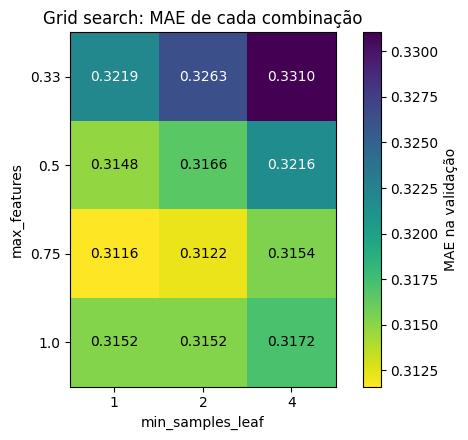

In [8]:
# cv_results_ guarda os resultados de TODAS as combinações. Vamos ver como tabela.
resultados_grade = pd.DataFrame(busca_grade.cv_results_)

# Uma tabela "dinâmica" (pivot): linhas = max_features, colunas = min_samples_leaf, valores = MAE.
mapa = resultados_grade.pivot(
    index="param_modelo__max_features",
    columns="param_modelo__min_samples_leaf",
    values="mean_test_score",
)
mapa = -mapa   # de volta para MAE positivo

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(mapa, cmap="viridis_r")   # _r inverte as cores: amarelo = menor erro
ax.set_xticks(range(len(mapa.columns)), mapa.columns)
ax.set_yticks(range(len(mapa.index)), mapa.index)
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_features")
for i in range(len(mapa.index)):
    for j in range(len(mapa.columns)):
        valor = mapa.iloc[i, j]
        # Texto preto nas células claras e branco nas escuras, para ficar legível.
        cor = "black" if valor < mapa.values.mean() else "white"
        ax.text(j, i, f"{valor:.4f}", ha="center", va="center", color=cor)
fig.colorbar(im, label="MAE na validação")
ax.set_title("Grid search: MAE de cada combinação")
plt.tight_layout()
plt.show()

**Conclusão:** a melhor combinação é **`max_features=0.75` com `min_samples_leaf=1`**, com MAE de **0,3116**. São os mesmos valores que já eram os melhores quando testamos cada hiperparâmetro sozinho.

O mapa de calor mostra uma **interação** entre os dois hiperparâmetros. Leia as linhas da esquerda para a direita:
- Com `max_features=0.33` (linha de cima), aumentar `min_samples_leaf` de 1 para 4 piora bastante o erro: de 0,3219 para 0,3310 (**+0,009**).
- Com `max_features=1.0` (linha de baixo), a mesma mudança quase não afeta o resultado: de 0,3152 para 0,3172 (**+0,002**).

Ou seja, o efeito de um hiperparâmetro **depende do valor do outro**. Faz sentido: com poucas colunas disponíveis, cada árvore já é "fraca", e simplificá-la ainda mais (folhas maiores) pesa muito. Esse tipo de interação é o motivo para buscar combinações em vez de ajustar um hiperparâmetro de cada vez.

O canto amarelo (0,75 e 1–2) está quase empatado: 0,3116 contra 0,3122.

In [9]:
# best_estimator_ é o pipeline com a melhor combinação, já RETREINADO com todos os
# dados de X_train_full (o GridSearchCV faz isso automaticamente no final, com refit=True).
melhor_grade = busca_grade.best_estimator_
avaliar_cv("Grid search", clone(melhor_grade))

Grid search: MAE 0.3116 ± 0.0045  (treino 0.116, 8.1 s)


## 🎓 Conceito: busca aleatória (Randomized Search)

A busca em grade tem dois problemas:
1. O custo explode com muitos hiperparâmetros.
2. Ela só testa os valores que **nós** escolhemos. Se o melhor `max_features` for 0,68, a grade nunca o encontra.

A **busca aleatória** sorteia combinações de **distribuições** (faixas de valores) e testa só um número fixo delas (`n_iter`). Parece pior, mas na prática costuma encontrar resultados tão bons quanto a grade, gastando muito menos. O motivo é que normalmente só **um ou dois** hiperparâmetros importam muito, e a busca aleatória testa muitos valores **diferentes** de cada um.

```
Busca em grade (9 testes)        Busca aleatória (9 testes)
  ·   ·   ·                        ·     ·
  ·   ·   ·                           ·      ·  ·
  ·   ·   ·                        ·    ·  ·    ·
  3 valores de cada                9 valores diferentes de cada
```

Para sortear, usamos as distribuições do `scipy.stats`:
- `uniform(início, largura)`: números decimais entre `início` e `início + largura`, todos com a mesma chance.
- `randint(mínimo, máximo)`: números inteiros de `mínimo` até `máximo − 1`.

## 6. RandomizedSearchCV

In [10]:
# Exemplo dos sorteadores: 5 sorteios de cada.
print("uniform(0.2, 0.8):", uniform(0.2, 0.8).rvs(5, random_state=0).round(3))   # decimais entre 0,2 e 1,0
print("randint(1, 10):   ", randint(1, 10).rvs(5, random_state=0))               # inteiros de 1 a 9

uniform(0.2, 0.8): [0.639 0.772 0.682 0.636 0.539]
randint(1, 10):    [6 1 4 4 8]


In [11]:
distribuicoes = {
    "modelo__max_features": uniform(0.2, 0.8),       # qualquer fração entre 0,2 e 1,0
    "modelo__min_samples_leaf": randint(1, 10),      # inteiros de 1 a 9
    "modelo__max_depth": [10, 20, 30, None],         # uma lista também vale: sorteia um item dela
}

busca_aleatoria = RandomizedSearchCV(
    pipeline,
    param_distributions=distribuicoes,
    n_iter=15,                          # testa 15 combinações sorteadas (15 × 5 = 75 florestas)
    cv=kfold,
    scoring="neg_mean_absolute_error",
    random_state=42,                    # torna o sorteio reproduzível
    return_train_score=True,
)

inicio = time.time()
busca_aleatoria.fit(X_train_full, y_train_full)
print(f"Tempo: {time.time() - inicio:.0f} s")
print("Melhor combinação:", busca_aleatoria.best_params_)
print(f"Melhor MAE (validação cruzada): {-busca_aleatoria.best_score_:.4f}")

Tempo: 70 s
Melhor combinação: {'modelo__max_depth': None, 'modelo__max_features': np.float64(0.9537614045478822), 'modelo__min_samples_leaf': 2}
Melhor MAE (validação cruzada): 0.3129


In [12]:
# As 15 combinações sorteadas, da melhor para a pior.
colunas = ["param_modelo__max_features", "param_modelo__min_samples_leaf", "param_modelo__max_depth",
           "mean_test_score", "std_test_score", "mean_train_score"]
tabela_aleatoria = pd.DataFrame(busca_aleatoria.cv_results_)[colunas].sort_values("mean_test_score", ascending=False)

# Renomeia as colunas para nomes mais curtos e troca o sinal dos scores.
tabela_aleatoria.columns = ["max_features", "min_samples_leaf", "max_depth", "MAE val", "± desvio", "MAE treino"]
tabela_aleatoria[["MAE val", "MAE treino"]] *= -1   # *= -1 multiplica a coluna por -1, no lugar
tabela_aleatoria["max_features"] = tabela_aleatoria["max_features"].astype(float).round(3)
tabela_aleatoria.round(4)

,max_features,min_samples_leaf,max_depth,MAE val,± desvio,MAE treino
13,0.954,2,None,0.3129,0.0042,0.1371
9,0.689,3,30,0.3133,0.0057,0.1676
5,0.866,6,None,0.3194,0.0059,0.2194
11,0.888,7,30,0.3224,0.0060,0.2317
0,0.837,8,30,0.3245,0.0058,0.2421
14,0.444,5,20,0.3286,0.0055,0.2249
10,0.611,9,None,0.3309,0.0060,0.2585
6,0.345,5,20,0.3349,0.0066,0.2355
4,0.216,2,30,0.3354,0.0049,0.1715
1,0.677,3,10,0.3448,0.0060,0.2750


**Conclusão:** a busca aleatória encontrou `max_features≈0.95` com `min_samples_leaf=2`, com MAE de **0,3129**. É um pouco pior que a grade (0,3116), mas a diferença é bem menor que o desvio padrão (~0,005). Na prática, empatou.

Por que não superou a grade?
- Testamos só **15** combinações num espaço **maior** (3 hiperparâmetros com faixas largas).
- **Todas** as combinações com `max_depth=10` ficaram entre as piores (MAE ≥ 0,344). A busca "gastou" 5 de 15 tentativas numa região ruim. Isso também é informação útil: agora sabemos que limitar tanto a profundidade é má ideia.

Repare também nas duas primeiras linhas: configurações **bem diferentes** (0,954 / 2 / None e 0,689 / 3 / 30) deram quase o mesmo erro (0,3129 e 0,3133). Isso indica que o "topo" é uma região **plana**: existem muitas configurações boas, e nenhuma é muito melhor que as outras.

A grande vantagem da busca aleatória é que ela **não exigiu saber de antemão** quais valores testar. Ela chegou perto do melhor resultado sozinha, só a partir de faixas largas.

## 🎓 Conceito: o melhor resultado de uma busca é otimista

Imagine que 15 alunos jogam uma moeda 10 vezes cada um. Algum deles vai tirar, por sorte, 8 ou 9 caras. Isso não significa que a moeda dele é especial.

Com hiperparâmetros acontece o mesmo. Quando testamos **muitas** combinações e escolhemos a **melhor**, parte da vantagem dela pode ser **sorte** nas dobras de validação. Por isso o `best_score_` tende a ser um pouco **otimista**. Isso tem até nome: **a maldição do vencedor**.

É por isso que:
1. Diferenças **menores que o desvio padrão** não devem ser levadas muito a sério.
2. A avaliação final precisa ser feita em dados que **não participaram da busca**: o **teste guardado**. Vamos fazer isso no notebook 07.

Vamos verificar se a vantagem do melhor modelo é consistente com uma **comparação pareada** (notebook 05).

## 7. A melhoria é real?

In [13]:
# Comparação dobra a dobra entre o modelo padrão e o melhor do grid search.
padrao = placar["Padrão"]["_por_dobra"]
ajustado = placar["Grid search"]["_por_dobra"]
diferencas = ajustado - padrao

print("MAE por dobra (padrão):  ", padrao.round(4))
print("MAE por dobra (ajustado):", ajustado.round(4))
print("Diferença:               ", diferencas.round(4))
print(f"\nO ajustado venceu em {(diferencas < 0).sum()} de 5 dobras.")
print(f"Melhoria média: {-diferencas.mean():.4f}  ({-diferencas.mean() / padrao.mean():.1%})")

MAE por dobra (padrão):   [0.3252 0.3133 0.3093 0.3178 0.3103]
MAE por dobra (ajustado): [0.3195 0.3129 0.3062 0.3105 0.3089]
Diferença:                [-0.0057 -0.0004 -0.0032 -0.0072 -0.0014]

O ajustado venceu em 5 de 5 dobras.
Melhoria média: 0.0036  (1.1%)


In [14]:
# O placar completo. drop(columns=...) esconde a coluna auxiliar com os valores por dobra.
pd.DataFrame(placar).T.drop(columns="_por_dobra").astype(float).round(4)

,MAE validação,± desvio,MAE treino,tempo (s)
Padrão,0.3152,0.0058,0.1167,9.2144
Grid search,0.3116,0.0045,0.1160,8.0717


**Conclusão:** o modelo ajustado (`max_features=0.75`) **venceu nas 5 dobras**, então a melhoria é **consistente**. Mas ela é **pequena**: 0,0036 de MAE (1,1%, cerca de US\$ 360), menor que o desvio padrão entre as dobras (~0,005).

Vamos **adotar** o modelo ajustado por três motivos:
1. Ele venceu em todas as dobras, então não é só sorte de uma divisão.
2. Ele é um pouco **mais rápido** de treinar, porque cada pergunta considera menos colunas.
3. Ele não acrescenta complexidade: é a mesma floresta, só com um número diferente.

Mas a lição mais importante é que **ajustar hiperparâmetros quase não mudou o resultado**. A random forest padrão já estava muito perto do melhor possível para este modelo e estes dados.

## 8. Quando vale a pena ajustar hiperparâmetros?

Compare a melhoria deste notebook com as dos anteriores (MAE de validação):

| Mudança | Melhoria no MAE |
|---|---|
| Baseline → regressão linear (nb 02) | −0,38 |
| Pré-processamento e atributos no linear (nb 03) | −0,06 |
| Linear → random forest (nb 04) | −0,13 |
| Atributos do nb 03 na floresta (nb 04) | −0,02 |
| **Ajuste de hiperparâmetros (nb 06)** | **−0,004** |

**A ordem de importância costuma ser esta:**
1. **Entender e preparar os dados**: limpeza, engenharia de atributos.
2. **Escolher a família certa de modelos**: linear, árvores, ensembles...
3. **Ajustar os hiperparâmetros**: o "polimento" final.

A random forest é famosa justamente por funcionar **bem com as configurações padrão**. Outros modelos são muito mais sensíveis, como o gradient boosting (notebook 08) e as redes neurais. Neles, o ajuste de hiperparâmetros faz uma diferença enorme, e as ferramentas que você aprendeu aqui são indispensáveis.

**Dicas práticas:**
- Comece pela **busca aleatória** com faixas largas. Depois, se quiser, refine com uma **grade** pequena em volta do melhor resultado.
- Compare sempre com o **modelo padrão** (comparação pareada). Muitas vezes a melhoria é ruído.
- Considere também o **tempo de treino**: entre dois modelos empatados, prefira o mais rápido e mais simples.

## 9. Resumo e próximos passos

**Conceitos que você aprendeu**
- Os hiperparâmetros da random forest: `n_estimators`, `max_features`, `min_samples_leaf` e `max_depth`.
- A notação **`etapa__hiperparametro`** e os métodos `get_params` e `set_params` em pipelines.
- **Grid search**: todas as combinações; caro, mas completo.
- **Random search**: combinações sorteadas de distribuições; mais eficiente com muitos hiperparâmetros.
- `best_params_`, `best_score_`, `best_estimator_` e `cv_results_`.
- **Diminuir o overfitting não é o objetivo**: o objetivo é o menor erro na validação.
- **A maldição do vencedor**: o melhor resultado de uma busca é otimista.
- Hiperparâmetros são **polimento**: os dados e a escolha do modelo importam mais.

**Python e bibliotecas novos:** `scipy.stats` (`uniform`, `randint`), `.rvs()`, `DataFrame.pivot`, `*=` e `.astype()`.

**Próximo notebook (07):** avaliação final e interpretação. Vamos avaliar o modelo ajustado no **teste guardado**, entender **o que** ele aprendeu (*permutation importance*), ver **onde** na Califórnia ele mais erra, **salvar o modelo** num arquivo e usá-lo para prever o preço de uma casa nova.